In [2]:
from PIL import Image
from skimage.util import img_as_float
import torchvision.transforms.functional as F

amlm1 = img_as_float(Image.open("images/amlm1.jpg"))
amlm2 = img_as_float(Image.open("images/amlm2.jpg"))
amlm3 = img_as_float(Image.open("images/amlm3.jpg"))
reference = img_as_float(Image.open("images/may-grunwald.jpg").convert('RGB'))


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.color import rgb2gray

def get_image(x):
    return x[0] if isinstance(x, tuple) else x


def plot_views(hasil1, hasil2, hasil3):
    plt.figure(figsize=(16, 4))

    for i, (image, label) in enumerate(zip(
        [reference, get_image(hasil1).clip(0, 1), get_image(hasil2).clip(0, 1), get_image(hasil3).clip(0, 1)],
        ["Reference", "AML M1", "AML M2", "AML M3"]
    )):
        plt.subplot(1, 4, i + 1)
        plt.imshow(image, cmap="gray")
        plt.title(label)
        plt.xticks([])
        plt.yticks([])

    plt.tight_layout()

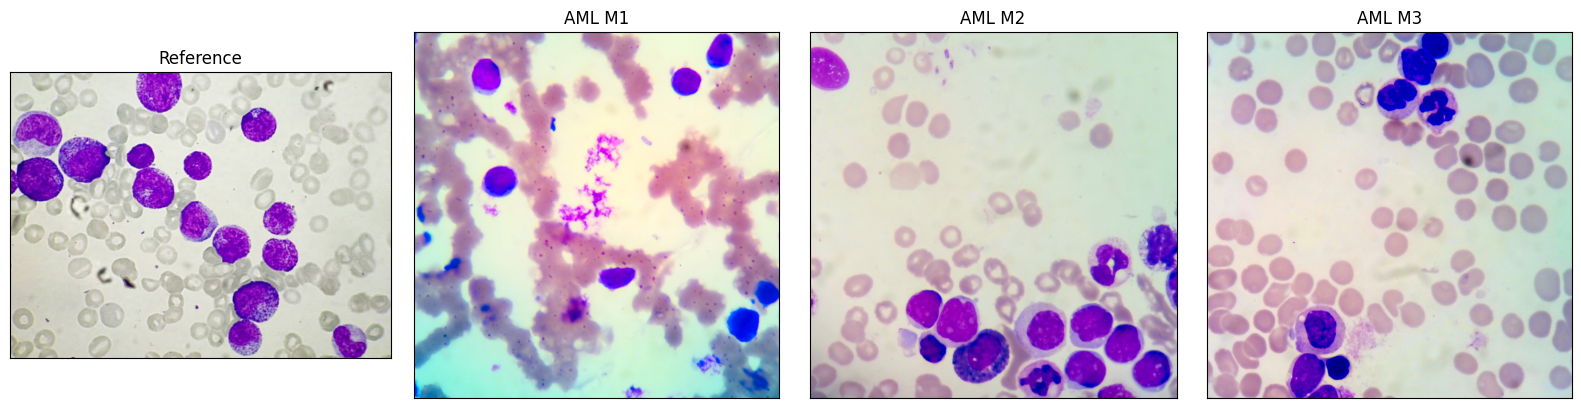

In [8]:
from methods.linear import color_transfer_between_images as ct
hasil1=ct(amlm1, reference)
hasil2=ct(amlm2, reference)
hasil3=ct(amlm3, reference)
plot_views(hasil1, hasil2, hasil3)

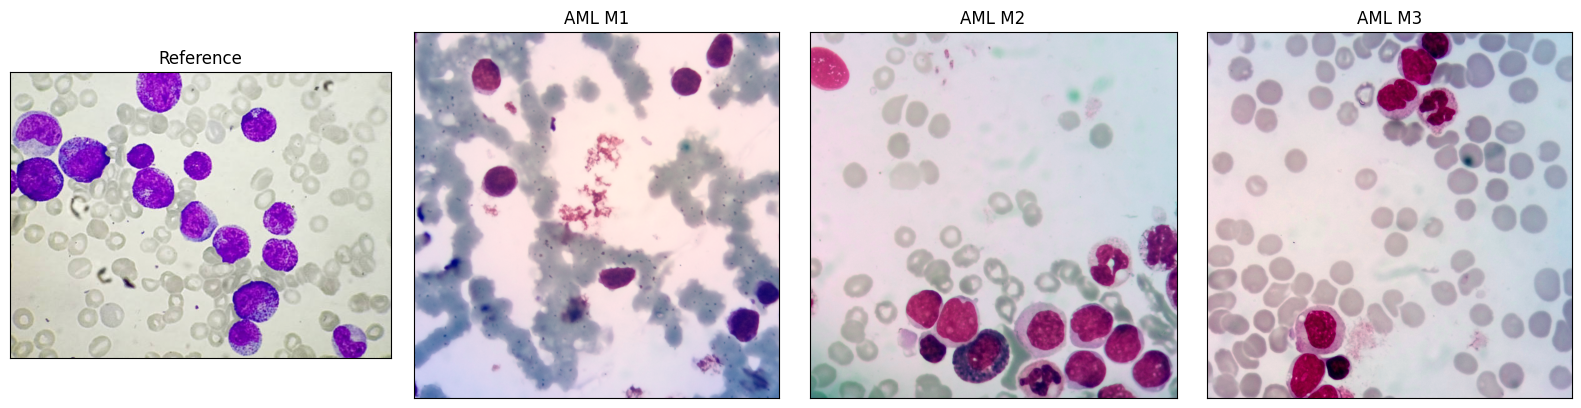

In [9]:
from methods.linear import color_transfer_in_correlated_color_space as ct_ccs
hasil1=ct_ccs(amlm1, reference)
hasil2=ct_ccs(amlm2, reference)
hasil3=ct_ccs(amlm3, reference)
plot_views(hasil1, hasil2, hasil3)

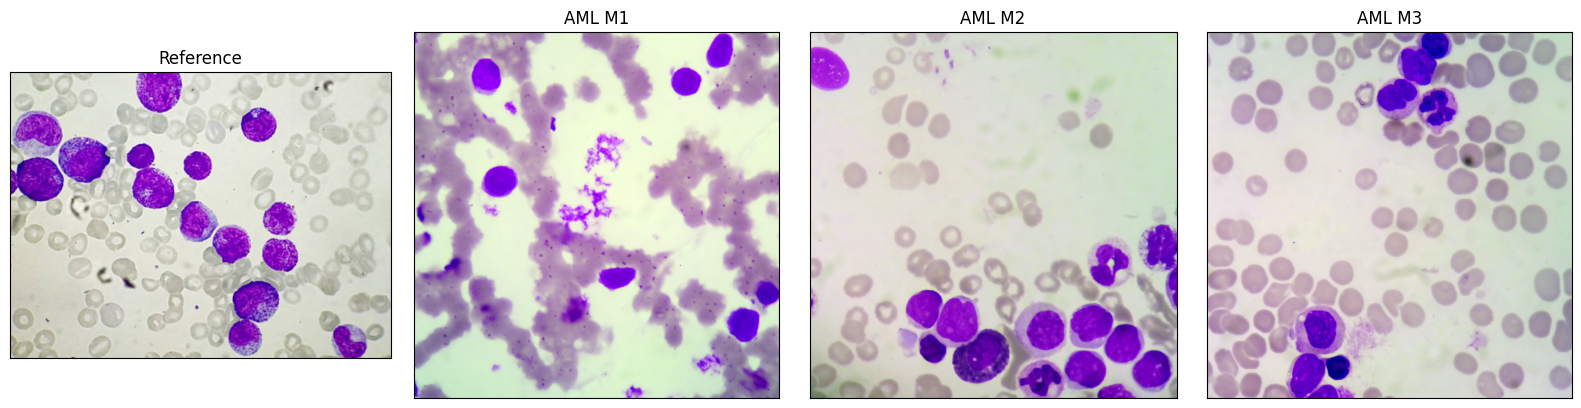

In [10]:
from methods.linear import monge_kantorovitch_color_transfer as mkct
hasil1=mkct(amlm1, reference)
hasil2=mkct(amlm2, reference)
hasil3=mkct(amlm3, reference)
plot_views(hasil1, hasil2, hasil3)

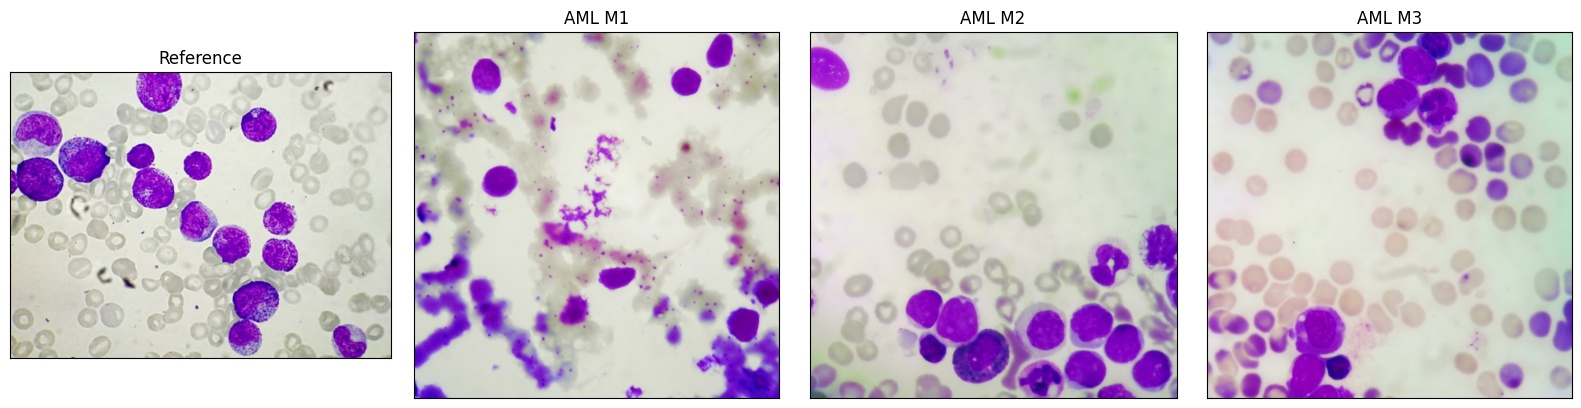

In [12]:
from methods.iterative import automated_color_grading as acg

hasil1=acg(amlm1, reference)
hasil2=acg(amlm2, reference)
hasil3=acg(amlm3, reference)
plot_views(hasil1, hasil2, hasil3)